# Experiment 20: Future Sales Prediction Using Machine Learning

**Aim:** To predict future sales using a Random Forest Regression algorithm.

**Dataset note:** This notebook generates a reproducible daily sales dataset with trend and weekly seasonality. The chronological split avoids using future observations to train a model that predicts earlier dates.

Sales dataset:


,Date,Sales
0,2024-01-01,505.48
1,2024-01-02,514.05
2,2024-01-03,555.51
3,2024-01-04,538.79
4,2024-01-05,453.53


Number of records: 240


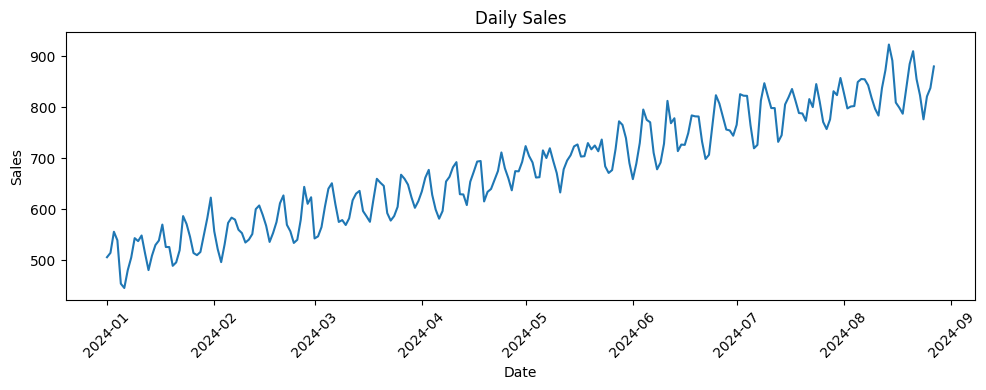

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Generate sample daily sales data
rng = np.random.default_rng(42)
dates = pd.date_range(start="2024-01-01", periods=240, freq="D")
day_number = np.arange(len(dates))
weekly_pattern = 40 * np.sin(2 * np.pi * day_number / 7)
trend = 1.5 * day_number
noise = rng.normal(0, 18, len(dates))
sales = 500 + trend + weekly_pattern + noise

df = pd.DataFrame({"Date": dates, "Sales": np.maximum(sales, 0).round(2)})

print("Sales dataset:")
display(df.head())
print("Number of records:", len(df))

plt.figure(figsize=(10, 4))
plt.plot(df["Date"], df["Sales"])
plt.title("Daily Sales")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [2]:
# Create lag and calendar features
data = df.copy()
data["Previous_Day"] = data["Sales"].shift(1)
data["Previous_Week"] = data["Sales"].shift(7)
data["Day_Of_Week"] = data["Date"].dt.dayofweek
data["Month"] = data["Date"].dt.month
data = data.dropna().reset_index(drop=True)

features = ["Previous_Day", "Previous_Week", "Day_Of_Week", "Month"]
X = data[features]
y = data["Sales"]

# Chronological train-test split
split_index = int(len(data) * 0.80)
X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
y_train, y_test = y.iloc[:split_index], y.iloc[split_index:]

# Train Random Forest Regressor
model = RandomForestRegressor(
    n_estimators=150, random_state=42
)
model.fit(X_train, y_train)

# Predict test period
y_pred = model.predict(X_test)

print("Actual sales:", y_test.to_numpy()[:10].round(2))
print("Predicted sales:", y_pred[:10].round(2))
print("Mean Absolute Error:", round(mean_absolute_error(y_test, y_pred), 2))
print("Root Mean Squared Error:", round(np.sqrt(mean_squared_error(y_test, y_pred)), 2))
print("R2 Score:", round(r2_score(y_test, y_pred), 4))

Actual sales: [798.45 732.08 745.12 805.58 819.67 835.9  812.91 788.72 787.84 773.36]
Predicted sales: [774.41 732.19 712.47 800.23 834.91 812.36 815.04 810.34 737.15 739.67]
Mean Absolute Error: 23.14
Root Mean Squared Error: 30.62
R2 Score: 0.4249


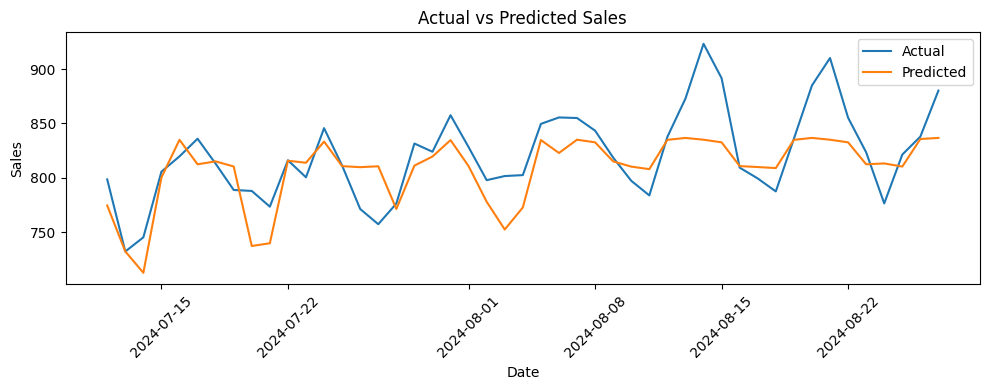

In [3]:
# Plot actual and predicted sales
plt.figure(figsize=(10, 4))
plt.plot(data["Date"].iloc[split_index:], y_test.to_numpy(), label="Actual")
plt.plot(data["Date"].iloc[split_index:], y_pred, label="Predicted")
plt.title("Actual vs Predicted Sales")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [4]:
# Predict sales for the next day using the latest observed values
last_date = df["Date"].iloc[-1]
next_date = last_date + pd.Timedelta(days=1)

next_input = pd.DataFrame([{
    "Previous_Day": df["Sales"].iloc[-1],
    "Previous_Week": df["Sales"].iloc[-7],
    "Day_Of_Week": next_date.dayofweek,
    "Month": next_date.month
}])

next_sales = model.predict(next_input[features])[0]
print("Next date:", next_date.date())
print("Predicted next-day sales:", round(next_sales, 2))

Next date: 2024-08-28
Predicted next-day sales: 835.0


## Result

A Random Forest Regression model was trained on historical sales features and used to predict future sales. Performance was evaluated using MAE, RMSE and R² score. The notebook also plots actual and predicted sales and estimates sales for the next day.